# 02 — Égalité femmes-hommes
Comparer les groupes puis examiner la composition des métiers et niveaux. Les différences observées ne démontrent ni causalité ni discrimination.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "data.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").exists():
    raise RuntimeError("Lancer depuis la racine du projet ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import load_data, export_table, attrition_table
from src.plots import plot_attrition, save_figure
df = load_data()


## Départs par genre
Les effectifs et nombres de départs accompagnent chaque proportion.

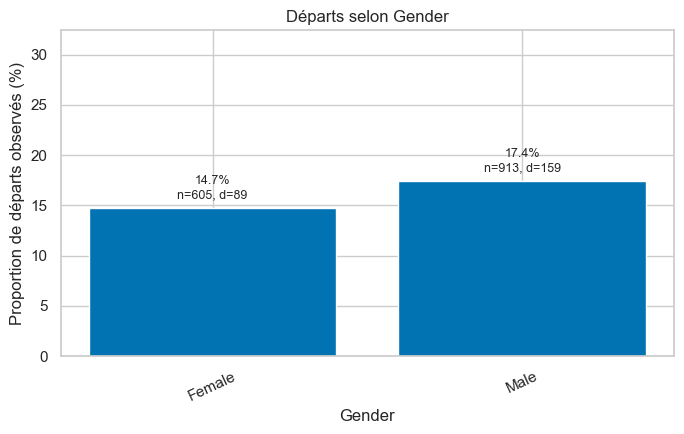

,Gender,effectif,departs,proportion_depart
0,Female,605,89,0.147107
1,Male,913,159,0.174151


In [2]:
genre = export_table(plot_attrition(df, "Gender", "02_depart_genre"), "02_depart_genre")
display(genre)

## Rémunération et indicateurs de parcours
`MonthlyIncome` est analysé sans présumer sa devise. `PercentSalaryHike` est un indicateur d’augmentation renseigné, de période inconnue. `YearsSinceLastPromotion` est un délai depuis la dernière promotion, jamais un taux de promotion ; l’absence d’historique des promotions empêche de mesurer une probabilité de promotion.

MonthlyIncome                      PercentSalaryHike                    \
               count         mean  median             count       mean median   
Gender                                                                          
Female           605  6703.066116  5154.0               605  15.206612   14.0   
Male             913  6378.242059  4821.0               913  15.224535   14.0   

       JobLevel                  YearsAtCompany                   \
          count      mean median          count      mean median   
Gender                                                             
Female      605  2.130579    2.0            605  7.221488    5.0   
Male        913  2.033954    2.0            913  6.845564    5.0   

       YearsInCurrentRole                  YearsSinceLastPromotion            \
                    count      mean median                   count      mean   
Gender                                                                         
Female                605  4.434711    3.0                     605  2.287603   
Male                  913  4.075575    3.0                     913  2.116101   

               
       median  
Gender         
Female    1.0  
Male      1.0

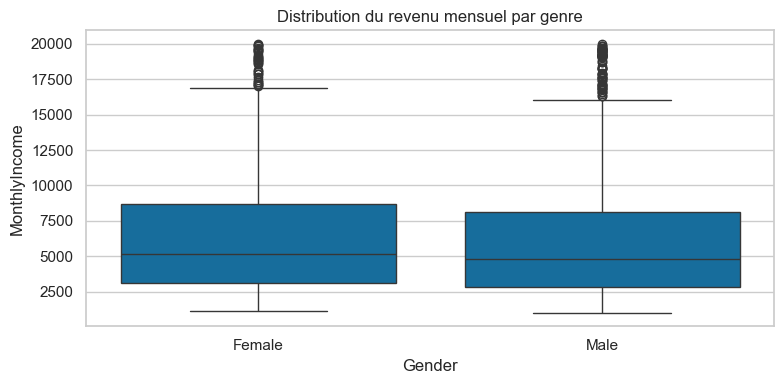

In [3]:
variables = ["MonthlyIncome", "PercentSalaryHike", "JobLevel", "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion"]
resume = df.groupby("Gender")[variables].agg(["count", "mean", "median"])
display(export_table(resume, "02_parcours_genre", index=True))
import seaborn as sns
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="Gender", y="MonthlyIncome", ax=ax)
ax.set_title("Distribution du revenu mensuel par genre")
save_figure(fig, "02_revenu_genre")

## Répartition hiérarchique et métiers
Les parts sont calculées à l’intérieur de chaque genre ; elles décrivent la composition des groupes.

In [4]:
for col in ["JobLevel", "JobRole"]:
    counts = pd.crosstab(df.Gender, df[col])
    display(export_table(counts, f"02_effectifs_{col}", index=True))
    display(export_table(counts.div(counts.sum(axis=1), axis=0), f"02_parts_{col}", index=True))

JobLevel,0,1,2,3,4,5
Gender,,,,,,
Female,2,202,224,96,54,27
Male,7,348,321,129,60,48


JobLevel,0,1,2,3,4,5
Gender,,,,,,
Female,0.003306,0.333884,0.370248,0.158678,0.089256,0.044628
Male,0.007667,0.381161,0.351588,0.141292,0.065717,0.052574


JobRole,Healthcare Representative,Human Resources,Laboratory Technician,Manager,Manufacturing Director,Research Director,Research Scientist,Sales Executive,Sales Representative
Gender,,,,,,,,,
Female,55,16,86,47,78,35,116,133,39
Male,82,38,181,56,74,49,184,200,49


JobRole,Healthcare Representative,Human Resources,Laboratory Technician,Manager,Manufacturing Director,Research Director,Research Scientist,Sales Executive,Sales Representative
Gender,,,,,,,,,
Female,0.090909,0.026446,0.142149,0.077686,0.128926,0.057851,0.191736,0.219835,0.064463
Male,0.089814,0.041621,0.198248,0.061336,0.081051,0.053669,0.201533,0.219058,0.053669


## Comparaisons à métier et niveau similaires
Chaque strate conserve ses effectifs. Un écart dans une petite strate est fragile. Les strates avec un seul genre ne permettent pas de comparaison.

In [5]:
strates = df.groupby(["JobRole", "JobLevel", "Gender"], observed=True).agg(
    effectif=("depart", "size"), departs=("depart", "sum"), proportion_depart=("depart", "mean"),
    revenu_moyen=("MonthlyIncome", "mean"), revenu_median=("MonthlyIncome", "median"),
    delai_promotion_moyen=("YearsSinceLastPromotion", "mean")) .reset_index()
display(export_table(strates, "02_strates_metier_niveau"))
revenus = strates.pivot(index=["JobRole", "JobLevel"], columns="Gender", values="revenu_moyen")
effectifs = strates.pivot(index=["JobRole", "JobLevel"], columns="Gender", values="effectif")
comparables = revenus.dropna(subset=["Female", "Male"]).copy()
comparables["ecart_femmes_hommes_pct"] = 100 * (comparables.Female / comparables.Male - 1)
comparables = comparables.join(effectifs.add_prefix("n_"))
display(export_table(comparables, "02_ecarts_comparables", index=True))

,JobRole,JobLevel,Gender,effectif,departs,proportion_depart,revenu_moyen,revenu_median,delai_promotion_moyen
0,Healthcare Representative,0,Female,1,0,0.000000,6376.000000,6376.0,12.000000
1,Healthcare Representative,2,Female,32,2,0.062500,6012.156250,5793.0,2.375000
2,Healthcare Representative,2,Male,47,1,0.021277,5853.808511,5745.0,1.659574
3,Healthcare Representative,3,Female,18,3,0.166667,8994.555556,8722.0,5.111111
4,Healthcare Representative,3,Male,28,2,0.071429,9379.000000,9854.0,3.250000
...,...,...,...,...,...,...,...,...,...
59,Sales Representative,1,Female,35,16,0.457143,2516.771429,2572.0,0.828571
60,Sales Representative,1,Male,41,16,0.390244,2498.146341,2476.0,1.000000
61,Sales Representative,2,Female,3,0,0.000000,4482.333333,4502.0,3.666667
62,Sales Representative,2,Male,6,2,0.333333,3398.333333,2943.0,1.500000


Gender                                    Female          Male  \
JobRole                   JobLevel                               
Healthcare Representative 2          6012.156250   5853.808511   
                          3          8994.555556   9379.000000   
                          4         12119.000000  12282.000000   
Human Resources           1          2653.000000   2768.086957   
                          2          5859.333333   5474.700000   
                          3          9514.333333   9980.500000   
Laboratory Technician     1          2821.208955   2873.574627   
                          2          4633.444444   4380.097561   
                          3          7403.000000   4293.000000   
Manager                   3         12376.000000  12032.800000   
                          4         16657.086957  16571.291667   
                          5         19133.705882  19166.629630   
Manufacturing Director    2          5294.162791   5908.142857   
                          3          9189.391304   9240.304348   
                          4         12502.000000  13687.500000   
Research Director         3         12652.000000  12814.333333   
                          4         16061.818182  16659.000000   
                          5         18424.000000  19105.450000   
Research Scientist        1          2887.534091   2798.771812   
                          2          4873.740741   4692.290323   
                          3          2975.000000   9724.000000   
Sales Executive           1          6348.000000   6228.000000   
                          2          5669.142857   5909.605839   
                          3          9075.407407   9150.730769   
                          4         13182.428571  12486.444444   
Sales Representative      0          2714.000000   2681.000000   
                          1          2516.771429   2498.146341   
                          2          4482.333333   3398.333333   

Gender                              ecart_femmes_hommes_pct  n_Female  n_Male  
JobRole                   JobLevel                                             
Healthcare Representative 2                        2.705038      32.0    47.0  
                          3                       -4.098992      18.0    28.0  
                          4                       -1.327145       4.0     7.0  
Human Resources           1                       -4.157635      10.0    23.0  
                          2                        7.025651       3.0    10.0  
                          3                       -4.670775       3.0     4.0  
Laboratory Technician     1                       -1.822318      67.0   134.0  
                          2                        5.784047      18.0    41.0  
                          3                       72.443513       1.0     3.0  
Manager                   3                        2.852204       7.0     5.0  
                          4                        0.517734      23.0    24.0  
                          5                       -0.171776      17.0    27.0  
Manufacturing Director    2                      -10.392099      43.0    49.0  
                          3                       -0.550989      23.0    23.0  
                          4                       -8.661187       9.0     2.0  
Research Director         3                       -1.266811      16.0    12.0  
                          4                       -3.584740      11.0    17.0  
                          5                       -3.566783       8.0    20.0  
Research Scientist        1                        3.171473      88.0   149.0  
                          2                        3.866990      27.0    31.0  
                          3                      -69.405594       1.0     1.0  
Sales Executive           1                        1.926782       1.0     1.0  
                          2                       -4.069019      98.0   137.0  
                   

## Lecture ajustée par standardisation descriptive
On applique les mêmes poids de métier/niveau aux deux genres, uniquement sur les strates communes. Cette comparaison réduit un effet de composition, sans ajuster l’expérience, les responsabilités réelles ou le temps de travail.

In [6]:
communes = strates.set_index(["JobRole", "JobLevel"]).loc[comparables.index].reset_index()
poids = communes.groupby(["JobRole", "JobLevel"]).effectif.sum()
poids = (poids / poids.sum()).rename("poids")
communes = communes.join(poids, on=["JobRole", "JobLevel"])
standard = communes.assign(revenu_pondere=lambda x: x.revenu_moyen*x.poids,
                           depart_pondere=lambda x: x.proportion_depart*x.poids)
display(export_table(standard.groupby("Gender")[["revenu_pondere", "depart_pondere"]].sum(), "02_standardisation", index=True))
print("Salariés couverts par les strates communes :", communes.effectif.sum(), "/", len(df))

,revenu_pondere,depart_pondere
Gender,,
Female,6475.520668,0.151975
Male,6554.898525,0.168462


Salariés couverts par les strates communes : 1505 / 1518


## Pistes RH à examiner
Auditer les grilles de rémunération et critères de mobilité par métier et niveau ; documenter les candidatures, promotions et augmentations avec dates ; suivre la représentation dans les postes de responsabilité. Ces actions doivent être discutées après lecture des résultats et validation des données. Aucune conclusion de discrimination ne peut reposer sur ces seules comparaisons.